# PDF 2 · Geometría de homografías y SVD (interactivo)

Este notebook convierte en dibujos dos ideas de la Sesión 2:

- **Parte A** (diapositivas 4–7): qué hace una homografía $H$ sobre una rejilla, y de dónde salen los puntos de fuga.
- **Parte B** (diapositivas 14–15): cómo se lee $A = U\,\Sigma\,V^T$ como cuatro pasos sobre un círculo.

Cómo usarlo: ejecuta las celdas **en orden** y mueve los deslizadores. Necesitas `ipywidgets` (en Jupyter Lab o VS Code funciona).

## Parte A · Homografía (diap. 4–7)

La diapositiva 7 divide la matriz de homografía en bloques:

$$H = \begin{pmatrix} A & t \\ v^T & h_{33} \end{pmatrix}, \qquad h_{33} = 1$$

- $A$ (2×2): rotación, escala y cizalla. En este notebook lo generamos como $A = s\,R(\theta)$.
- $t$ (2×1): traslación.
- $v$ (2×1): parte proyectiva. Si $v = 0$, las rectas paralelas siguen siendo paralelas. Si $v \neq 0$, aparecen puntos de fuga.

Un punto $p = (x, y)$ se transforma con $H$ usando coordenadas homogéneas (diap. 4):

$$\begin{pmatrix} x' \\ y' \\ w' \end{pmatrix} = H \begin{pmatrix} x \\ y \\ 1 \end{pmatrix}, \qquad \text{punto final} = \left(\frac{x'}{w'},\ \frac{y'}{w'}\right)$$

**Puntos de fuga.** La dirección horizontal del plano es el punto del infinito $(1, 0, 0)^T$. Su imagen es $H\,(1,0,0)^T = (h_{11}, h_{21}, h_{31})^T$, que en la imagen queda en $\left(\frac{h_{11}}{h_{31}}, \frac{h_{21}}{h_{31}}\right)$. Todas las rectas horizontales convergen en ese punto. Lo mismo ocurre con la dirección vertical $(0, 1, 0)^T$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import FloatSlider, interactive
from IPython.display import display

np.set_printoptions(precision=3, suppress=True)

def rejilla(paso=0.25, lim=1.5, n=80):
    # Segmentos de una rejilla cuadrada en [-lim, lim]^2
    segs = []
    t = np.linspace(-lim, lim, n)
    for c in np.arange(-lim, lim + 1e-9, paso):
        segs.append(np.c_[np.full(n, c), t])   # recta x = c
        segs.append(np.c_[t, np.full(n, c)])   # recta y = c
    return segs

def aplica_H(H, pts):
    # Aplica H a cada punto (fila de pts) y hace la división homogénea
    P = np.c_[pts, np.ones(len(pts))]
    Q = P @ H.T
    w = Q[:, 2]
    return Q[:, :2] / w[:, None], w

def construye_H(theta_deg, s, tx, ty, v1, v2):
    th = np.deg2rad(theta_deg)
    R = np.array([[np.cos(th), -np.sin(th)],
                  [np.sin(th),  np.cos(th)]])
    A = s * R
    return np.array([[A[0, 0], A[0, 1], tx],
                     [A[1, 0], A[1, 1], ty],
                     [v1,      v2,      1.0]])

def dibuja_homografia(theta=20.0, s=1.0, tx=0.0, ty=0.0, v1=0.0, v2=0.0):
    H = construye_H(theta, s, tx, ty, v1, v2)
    print("H =")
    print(H)

    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5.5))
    L = 6.0

    segs = rejilla()
    for seg in segs:
        ax0.plot(seg[:, 0], seg[:, 1], color="tab:blue", lw=0.8)
    ax0.set_title("Original (plano)")

    for seg in segs:
        q, w = aplica_H(H, seg)
        malo = (np.abs(w) < 0.05) | (np.abs(q).max(axis=1) > L)
        q = q.copy()
        q[malo] = np.nan              # se corta donde el punto va al infinito
        ax1.plot(q[:, 0], q[:, 1], color="tab:orange", lw=0.8)

    # Puntos de fuga: imagen de las direcciones del infinito
    for d, nombre, color in [((1, 0, 0), "fuga horizontal", "tab:red"),
                             ((0, 1, 0), "fuga vertical", "tab:green")]:
        p = H @ np.array(d, dtype=float)
        if abs(p[2]) > 1e-6:
            x, y = p[0] / p[2], p[1] / p[2]
            if abs(x) < L and abs(y) < L:
                ax1.plot(x, y, "o", color=color, ms=8, label=f"{nombre} ({x:.2f}, {y:.2f})")
    if ax1.get_legend_handles_labels()[0]:
        ax1.legend(loc="upper right", fontsize=8)

    for ax, titulo in [(ax0, "Original (plano)"), (ax1, "Tras H (imagen)")]:
        ax.set_xlim(-L, L); ax.set_ylim(-L, L)
        ax.set_aspect("equal")
        ax.axhline(0, color="gray", lw=0.4); ax.axvline(0, color="gray", lw=0.4)
        ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

w_homo = interactive(
    dibuja_homografia,
    theta=FloatSlider(value=20.0, min=-180.0, max=180.0, step=5.0, description="θ (°)"),
    s=FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1, description="escala s"),
    tx=FloatSlider(value=0.0, min=-3.0, max=3.0, step=0.1, description="t_x"),
    ty=FloatSlider(value=0.0, min=-3.0, max=3.0, step=0.1, description="t_y"),
    v1=FloatSlider(value=0.0, min=-0.5, max=0.5, step=0.01, description="v₁"),
    v2=FloatSlider(value=0.0, min=-0.5, max=0.5, step=0.01, description="v₂"),
)
display(w_homo)

interactive(children=(FloatSlider(value=20.0, description='θ (°)', max=180.0, min=-180.0, step=5.0), FloatSlid…

H =
[[ 1.08756934 -0.50714191  0.5       ]
 [ 0.50714191  1.08756934 -0.3       ]
 [ 0.35        0.1         1.        ]]


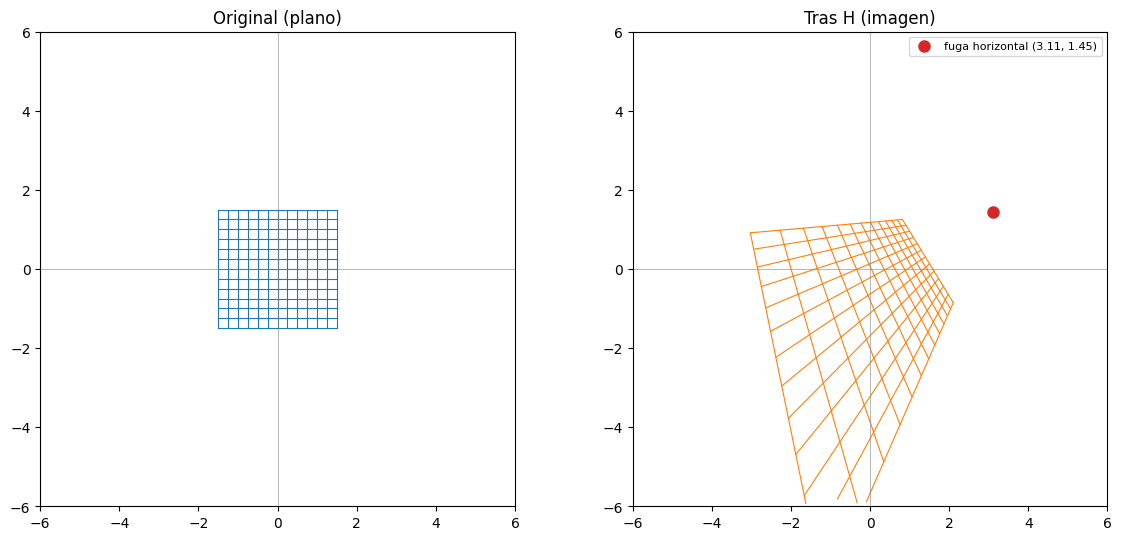

In [2]:
# Versión estática, con valores fijos (se ve aunque no haya deslizadores)
dibuja_homografia(theta=25, s=1.2, tx=0.5, ty=-0.3, v1=0.35, v2=0.1)

### Qué mirar en la Parte A

1. Con $v_1 = v_2 = 0$ (la parte proyectiva es cero), las rectas paralelas siguen siendo paralelas: no hay puntos de fuga en la imagen.
2. Mueve $v_1$ o $v_2$ a un valor distinto de cero. Aparecen los puntos de fuga (puntos rojo y verde) y las rectas paralelas empiezan a converger. Esa es la única parte de $H$ que rompe el paralelismo (diap. 7).
3. Con cualquier valor de $\theta$, $s$, $t$, las rectas siguen siendo rectas (diap. 5). Esa propiedad no depende de los parámetros.

## Parte B · SVD como geometría (diap. 14–15)

La diapositiva 15 muestra que $A = U\,\Sigma\,V^T$ se puede leer como tres pasos sobre un círculo de radio 1:

1. $V^T$ **rota** el círculo (sigue siendo un círculo).
2. $\Sigma$ **estira** el círculo a lo largo de los ejes: queda una elipse alineada con los ejes.
3. $U$ **rota** la elipse. El resultado es $A\cdot\text{círculo}$.

En este notebook seguimos la trayectoria de dos vectores especiales, $v_1$ y $v_2$ (columnas de $V$):

- Tras el paso 1 quedan como $e_1$ y $e_2$, los ejes canónicos.
- Tras el paso 2 quedan como $\sigma_1 e_1$ y $\sigma_2 e_2$.
- Tras el paso 3 quedan como $\sigma_1 u_1$ y $\sigma_2 u_2$, porque $A v_i = \sigma_i u_i$.

Los valores singulares $\sigma_1 \geq \sigma_2$ son los semiejes de la elipse final, y el número de condición es $\kappa = \sigma_1 / \sigma_2$ (diap. 14).

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import FloatSlider, interactive
from IPython.display import display

np.set_printoptions(precision=3, suppress=True)

def dibuja_svd(a11=2.0, a12=0.0, a21=1.0, a22=1.5):
    A = np.array([[a11, a12], [a21, a22]])
    U, s, Vt = np.linalg.svd(A)
    S = np.diag(s)
    assert np.allclose(U @ S @ Vt, A)     # comprobación de A = U Σ Vᵀ

    t = np.linspace(0, 2 * np.pi, 400)
    circ = np.vstack([np.cos(t), np.sin(t)])

    pasos = [("1. Círculo original", np.eye(2)),
             ("2. Vᵀ: rotación", Vt),
             ("3. Σ: estiramiento", S @ Vt),
             ("4. U: rotación  (= A·círculo)", A)]

    L = max(2.0, 1.3 * s[0])
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
    for ax, (titulo, M) in zip(axes, pasos):
        P = M @ circ
        ax.plot(P[0], P[1], color="tab:blue", lw=1.6)
        for i, color in [(0, "tab:red"), (1, "tab:green")]:
            vec = M @ Vt[i]           # Vt[i] es v_i (columna i de V)
            ax.annotate("", xy=vec, xytext=(0, 0),
                        arrowprops=dict(arrowstyle="->", color=color, lw=2))
        ax.axhline(0, color="gray", lw=0.4); ax.axvline(0, color="gray", lw=0.4)
        ax.set_xlim(-L, L); ax.set_ylim(-L, L)
        ax.set_aspect("equal")
        ax.set_title(titulo, fontsize=11)

    kappa = s[0] / s[1] if s[1] > 1e-12 else np.inf
    fig.suptitle(f"σ₁ = {s[0]:.3f},  σ₂ = {s[1]:.3f},  κ = σ₁/σ₂ = {kappa:.2f}   "
                 f"(rojo: v₁ · verde: v₂)", fontsize=12)
    plt.tight_layout()
    plt.show()

    print("A =\n", A)
    print("U =\n", U)
    print("Σ =\n", S)
    print("Vᵀ =\n", Vt)

w_svd = interactive(
    dibuja_svd,
    a11=FloatSlider(value=2.0, min=-2.0, max=2.0, step=0.1, description="a₁₁"),
    a12=FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, description="a₁₂"),
    a21=FloatSlider(value=1.0, min=-2.0, max=2.0, step=0.1, description="a₂₁"),
    a22=FloatSlider(value=1.5, min=-2.0, max=2.0, step=0.1, description="a₂₂"),
)
display(w_svd)

interactive(children=(FloatSlider(value=2.0, description='a₁₁', max=2.0, min=-2.0), FloatSlider(value=0.0, des…

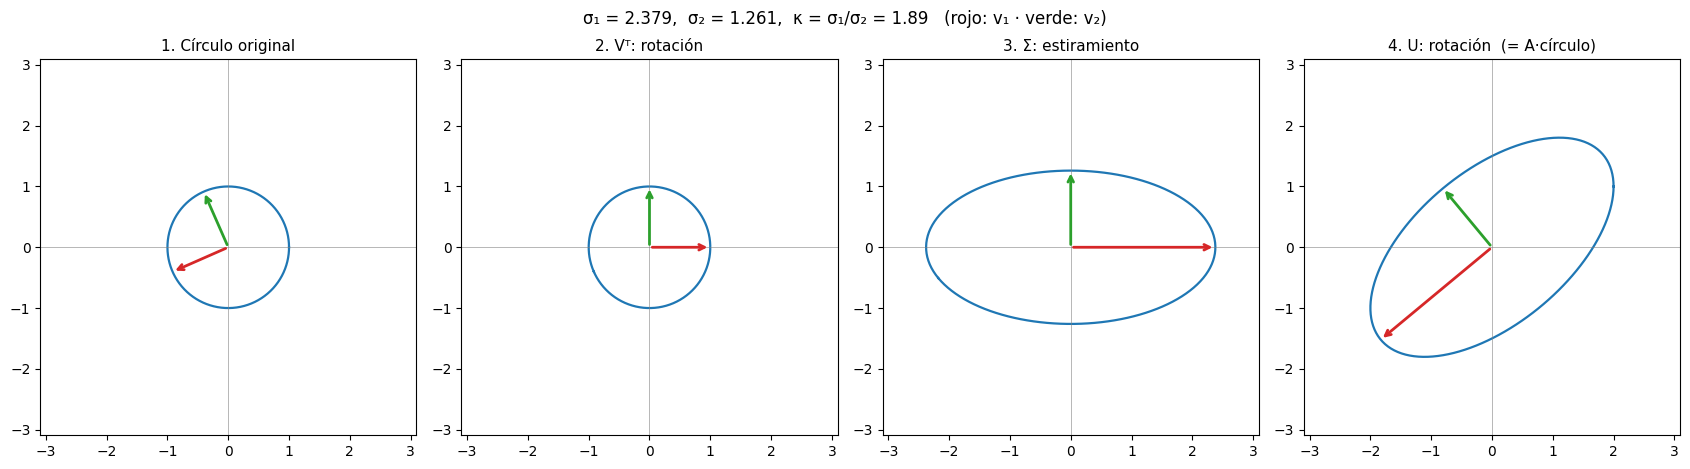

A =
 [[2.  0. ]
 [1.  1.5]]
U =
 [[-0.76950911 -0.63863584]
 [-0.63863584  0.76950911]]
Σ =
 [[2.37904447 0.        ]
 [0.         1.26101048]]
Vᵀ =
 [[-0.91534819 -0.40266324]
 [-0.40266324  0.91534819]]


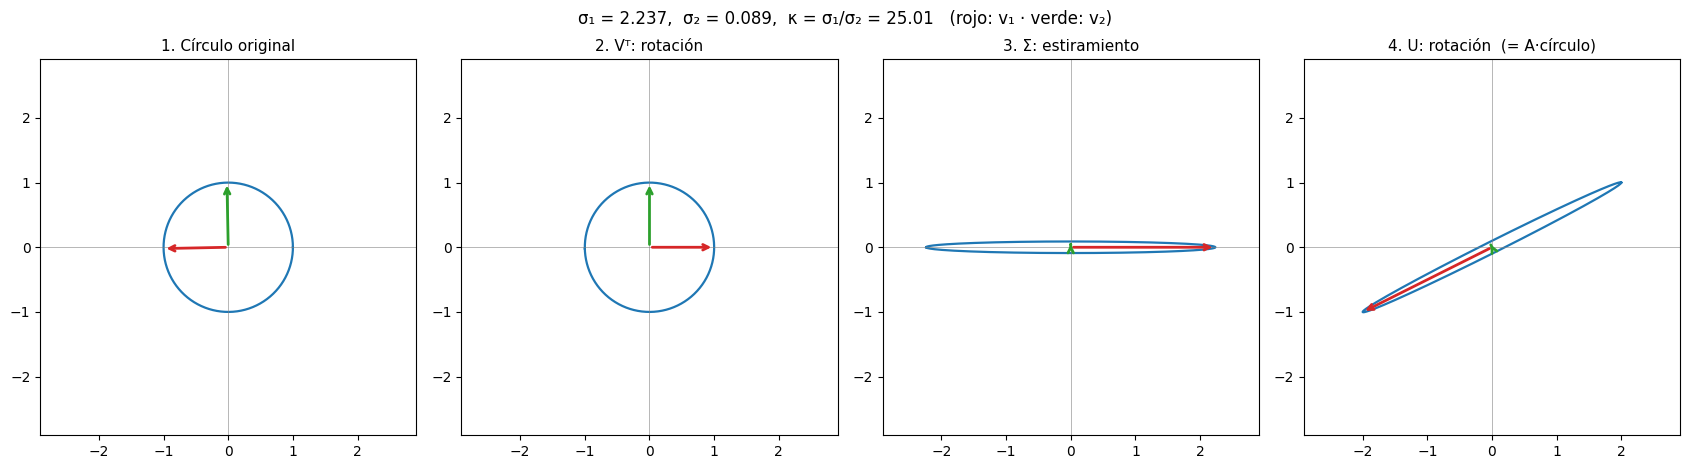

A =
 [[2.  0. ]
 [1.  0.1]]
U =
 [[-0.8940687  -0.44792985]
 [-0.44792985  0.8940687 ]]
Σ =
 [[2.23651586 0.        ]
 [0.         0.08942481]]
Vᵀ =
 [[-0.99979942 -0.02002802]
 [-0.02002802  0.99979942]]


In [4]:
# Versión estática: matriz general, y otra casi singular (σ₂ pequeño, κ grande)
dibuja_svd()
dibuja_svd(a11=2.0, a12=0.0, a21=1.0, a22=0.1)

### Qué mirar en la Parte B

1. Pon $a_{12} = a_{21} = 0$ y $a_{11} = a_{22}$: la matriz es un múltiplo de la identidad, la elipse es un círculo y $\sigma_1 = \sigma_2$, así que $\kappa = 1$.
2. Pon $a_{11}$ y $a_{22}$ en valores distintos: la elipse se alarga. La rotación $V^T$ solo cambia la orientación de la entrada, y $\Sigma$ estira en los ejes.
3. Acerca $a_{22}$ a cero (por ejemplo, $a_{11} = 2$, $a_{21} = 1$, $a_{22} = 0$, $a_{12}=0$), o haz que las dos filas sean casi proporcionales. Entonces $\sigma_2 \to 0$, la elipse se aplasta en una línea y $\kappa$ crece sin límite.

El último caso es la inestabilidad de la diap. 12 y 14: cuando $\sigma_n$ es casi cero, dividir por él amplifica cualquier error de medida. En el DLT, esto es lo que hace que los errores de píxel se disparen si no normalizamos los puntos (diap. 20–21).